# Etapa 0. Ingesta y buffer (cola FIFO)

**Proyecto EDA 2026-2, Grupo 1, escenario B (comercio electrónico).**
Responsable de las etapas 0, 1 y 2: Cristina.

## Función de la etapa en el pipeline

La etapa 0 es la puerta de entrada del pipeline. Recibe un flujo continuo de eventos de comercio electrónico y lo guarda temporalmente en un buffer FIFO. Después entrega esos eventos a la etapa 1 en micro-lotes. El buffer desacopla la velocidad del productor (el generador de eventos) de la velocidad del consumidor (el preprocesamiento). Cuando el consumidor es más lento, el buffer se llena y el productor espera. Este mecanismo se llama backpressure.

## Pasos del notebook

1. Configuración del entorno y semilla.
2. Lectura del dataset como stream, sin cargarlo completo en RAM.
3. Carga del catálogo de productos (precio, categoría y título).
4. Generador sintético de eventos de comercio electrónico.
5. Implementación propia de la cola FIFO (buffer circular y lista enlazada).
6. Buffer con backpressure y formación de micro-lotes.
7. Ejecución de la etapa 0 y métricas observadas.
8. Experimentos de complejidad (tiempo y memoria) frente a `list.pop(0)` y `collections.deque`.
9. Salida de la etapa 0 para la etapa 1.

## Paso 1. Configuración

Se importan las librerías y se fijan los parámetros globales.

- `SEED = 42` hace que el generador produzca siempre los mismos eventos. Esto permite repetir los experimentos.
- `RAIZ` es la carpeta raíz del proyecto. Se busca subiendo desde la carpeta actual hasta encontrar la carpeta que contiene `notebooks/` y `data/`, para que el notebook funcione aunque se abra desde otra ubicación.
- Los datos crudos se leen de `data/raw/`, que se llena con `python scripts/data_download.py All_Beauty`.
- Los resultados de los experimentos se guardan como CSV en `results/`, y la salida de la etapa en `data/interim/<CATEGORIA>/`. Los archivos que dependen de la categoría llevan su nombre, así los resultados de distintas categorías no se sobrescriben. Para procesar otra categoría basta con cambiar `CATEGORIA` en este notebook.

In [1]:
import gc
import json
import platform
import random
import re
import statistics
import sys
import threading
import time
import tracemalloc
import zlib
import heapq                      # solo se usa dentro del simulador (paso 4), no es una estructura evaluada
from collections import Counter, deque
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil

# Semilla fija para reproducibilidad
SEED = 42

# Raíz del proyecto: se sube de carpeta hasta encontrar la que contiene notebooks/ y data/
RAIZ = Path.cwd()
while not ((RAIZ / "notebooks").is_dir() and (RAIZ / "data").is_dir()) and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent

CATEGORIA = "All_Beauty"   # categoría de desarrollo
RUTA_RESENAS = RAIZ / "data" / "raw" / "review_categories" / f"{CATEGORIA}.jsonl"
RUTA_META = RAIZ / "data" / "raw" / "meta_categories" / f"meta_{CATEGORIA}.jsonl"

CARPETA_RESULTADOS = RAIZ / "results"
CARPETA_INTERIM = RAIZ / "data" / "interim" / CATEGORIA   # una carpeta por categoría
CARPETA_RESULTADOS.mkdir(exist_ok=True)
CARPETA_INTERIM.mkdir(parents=True, exist_ok=True)

assert RUTA_RESENAS.exists(), "Falta el archivo de reseñas. Ejecutar: python scripts/data_download.py All_Beauty"
assert RUTA_META.exists(), "Falta el archivo de metadatos. Ejecutar: python scripts/data_download.py All_Beauty"

# Plataforma (el enunciado pide reportarla junto con la semilla)
PLATAFORMA = {
    "sistema": platform.platform(),
    "procesador": platform.processor(),
    "nucleos": psutil.cpu_count(logical=True),
    "ram_gb": round(psutil.virtual_memory().total / 1e9, 1),
    "python": platform.python_version(),
    "semilla": SEED,
}
PLATAFORMA

{'sistema': 'Windows-10-10.0.26200-SP0',
 'procesador': 'Intel64 Family 6 Model 158 Stepping 10, GenuineIntel',
 'nucleos': 12,
 'ram_gb': 17.0,
 'python': '3.11.1',
 'semilla': 42}

## Paso 2. El dataset como stream

El archivo de reseñas tiene unas 700 000 líneas y pesa unos 310 MB. Cada línea es un objeto JSON (formato JSONL). En lugar de cargarlo completo en una lista, se recorre con un **generador** de Python (`yield`). Un generador produce un registro cuando se le pide y no guarda los anteriores. Por eso la memoria usada se mantiene casi constante, sin importar cuántas reseñas se lean.

Esta decisión se justifica en el informe con cuatro argumentos.

- El disco y la RAM son recursos distintos. El archivo ocupa disco, pero procesarlo completo en una lista ocuparía RAM, que es más escasa.
- Un stream real no tiene fin, así que no es posible cargar todo y procesarlo después.
- La memoria del generador es O(1) respecto al número de reseñas, mientras que una lista ocupa O(n).
- Los resultados salen desde el primer registro, lo que reduce la latencia.

De cada reseña se conservan solo los campos que usa el generador de eventos.

In [2]:
def leer_resenas(ruta, limite=None):
    """Recorre el archivo JSONL de reseñas línea por línea y entrega un registro a la vez.

    limite: número máximo de reseñas a leer (None lee el archivo completo).
    """
    with open(ruta, "r", encoding="utf-8") as archivo:
        for i, linea in enumerate(archivo):
            if limite is not None and i >= limite:
                break
            r = json.loads(linea)
            # Solo se guardan los campos necesarios para generar eventos
            yield {
                "user_id": r["user_id"],
                "parent_asin": r["parent_asin"],
                "rating": r["rating"],
                "verified_purchase": r["verified_purchase"],
            }


# Ejemplo: las tres primeras reseñas
for resena in leer_resenas(RUTA_RESENAS, limite=3):
    print(resena)

{'user_id': 'AGKHLEW2SOWHNMFQIJGBECAF7INQ', 'parent_asin': 'B00YQ6X8EO', 'rating': 5.0, 'verified_purchase': True}
{'user_id': 'AGKHLEW2SOWHNMFQIJGBECAF7INQ', 'parent_asin': 'B081TJ8YS3', 'rating': 4.0, 'verified_purchase': True}
{'user_id': 'AE74DYR3QUGVPZJ3P7RFWBGIX7XQ', 'parent_asin': 'B097R46CSY', 'rating': 5.0, 'verified_purchase': True}


### Comprobación empírica: generador frente a lista

Se mide la memoria pico con `tracemalloc` al recorrer 100 000 reseñas de dos formas. La primera usa el generador y la segunda guarda todo en una lista antes de recorrerla. El número de reseñas leídas es el mismo en ambos casos.

In [3]:
def memoria_pico_mb(funcion):
    """Ejecuta funcion() y devuelve la memoria pico (MB) registrada por tracemalloc."""
    gc.collect()
    tracemalloc.start()
    funcion()
    _, pico = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return pico / 1e6


N_PRUEBA = 100_000

def recorrer_con_generador():
    total = 0
    for _ in leer_resenas(RUTA_RESENAS, N_PRUEBA):
        total += 1
    return total

def recorrer_con_lista():
    todas = list(leer_resenas(RUTA_RESENAS, N_PRUEBA))   # todo queda en RAM
    total = 0
    for _ in todas:
        total += 1
    return total

pico_gen = memoria_pico_mb(recorrer_con_generador)
pico_lista = memoria_pico_mb(recorrer_con_lista)
print(f"Memoria pico con generador: {pico_gen:8.2f} MB")
print(f"Memoria pico con lista:     {pico_lista:8.2f} MB")
print(f"La lista usa {pico_lista / pico_gen:.0f} veces más memoria para {N_PRUEBA:,} reseñas.")

Memoria pico con generador:     0.06 MB
Memoria pico con lista:        35.23 MB
La lista usa 544 veces más memoria para 100,000 reseñas.


### Rendimiento al crecer el número de reseñas

La comprobación anterior usa un solo tamaño. Para ver cómo escala cada forma de lectura se repite con 1K, 10K, 50K, 100K y 200K reseñas y se miden tres cosas.

- **Memoria pico** con `tracemalloc`. Con la lista se espera O(n), porque guarda todas las reseñas; con el generador, O(1), porque guarda una sola a la vez.
- **Tiempo hasta el primer registro**, es decir, cuánto tarda el consumidor en tener el primer registro para procesar. Es la latencia de arranque del pipeline. La lista debe leer el archivo completo antes de entregar algo; el generador entrega el primero tras leer una línea.
- **Tiempo total** de recorrer todas las reseñas. Sirve para comprobar que el generador no paga su ahorro de memoria con más tiempo.

La memoria se mide en una ejecución aparte de los tiempos, porque `tracemalloc` hace más lento el código que observa. Los tiempos son el promedio de 5 repeticiones. Los resultados se guardan en `results/etapa0_stream_vs_lista_<CATEGORIA>.csv` y se reutilizan si el archivo existe; para medir de nuevo se cambia `REEJECUTAR_STREAM` a `True`.

Resultados leídos de results\etapa0_stream_vs_lista_All_Beauty.csv


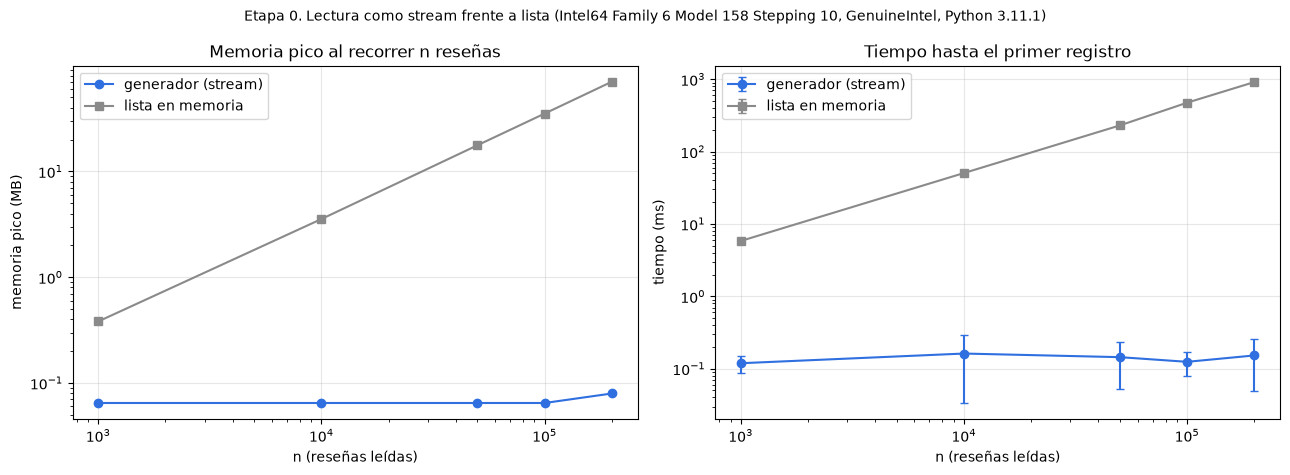

memoria_pico_mb         primer_registro_ms            total_s       
forma        generador   lista          generador    lista generador  lista
n                                                                          
1000             0.065   0.382              0.119    5.818     0.006  0.006
10000            0.065   3.548              0.162   50.522     0.048  0.054
50000            0.065  17.674              0.144  230.080     0.225  0.229
100000           0.065  35.232              0.124  473.733     0.498  0.456
200000           0.080  70.451              0.152  912.435     0.901  0.916

Con 200,000 reseñas:
  memoria pico:         lista 70.5 MB, generador 0.08 MB (886 veces menos)
  primer registro:      lista 912 ms, generador 0.152 ms
  recorrido completo:   lista 0.92 s, generador 0.90 s


In [4]:
REEJECUTAR_STREAM = False
TAMANOS_STREAM = [1_000, 10_000, 50_000, 100_000, 200_000]
REPETICIONES_STREAM = 5
ruta_stream = CARPETA_RESULTADOS / f"etapa0_stream_vs_lista_{CATEGORIA}.csv"


def primer_registro(forma, n):
    """Segundos hasta tener el primer registro disponible para procesar."""
    t0 = time.perf_counter()
    if forma == "generador":
        lector = leer_resenas(RUTA_RESENAS, n)
        next(lector)                       # basta leer una línea
        lector.close()                     # cierra el archivo sin leer el resto
    else:
        todas = list(leer_resenas(RUTA_RESENAS, n))   # hay que leer todo antes
        todas[0]
    return time.perf_counter() - t0


def recorrido_completo(forma, n):
    """Segundos para recorrer las n reseñas."""
    t0 = time.perf_counter()
    fuente = leer_resenas(RUTA_RESENAS, n) if forma == "generador" else list(leer_resenas(RUTA_RESENAS, n))
    for _ in fuente:
        pass
    return time.perf_counter() - t0


def pico_de(forma, n):
    """Memoria pico (MB) al recorrer las n reseñas."""
    def recorrer():
        fuente = leer_resenas(RUTA_RESENAS, n) if forma == "generador" else list(leer_resenas(RUTA_RESENAS, n))
        for _ in fuente:
            pass
    return memoria_pico_mb(recorrer)


if ruta_stream.exists() and not REEJECUTAR_STREAM:
    stream_vs_lista = pd.read_csv(ruta_stream)
    print(f"Resultados leídos de {ruta_stream.relative_to(RAIZ)}")
else:
    filas = []
    for n in TAMANOS_STREAM:
        for forma in ["generador", "lista"]:
            primeros = [primer_registro(forma, n) for _ in range(REPETICIONES_STREAM)]
            totales = [recorrido_completo(forma, n) for _ in range(REPETICIONES_STREAM)]
            filas.append({"forma": forma, "n": n,
                          "memoria_pico_mb": pico_de(forma, n),
                          "primer_registro_ms": statistics.mean(primeros) * 1000,
                          "primer_registro_desv_ms": statistics.stdev(primeros) * 1000,
                          "total_s": statistics.mean(totales),
                          "total_desv_s": statistics.stdev(totales)})
        print(f"n = {n:>7,} medido")
    stream_vs_lista = pd.DataFrame(filas)
    stream_vs_lista.to_csv(ruta_stream, index=False)

# --- Gráficas -------------------------------------------------------------------
estilo = {"generador": dict(marker="o", color="#2f6fe0", label="generador (stream)"),
          "lista": dict(marker="s", color="#8a8a8a", label="lista en memoria")}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
for forma, datos in stream_vs_lista.groupby("forma"):
    ax1.plot(datos["n"], datos["memoria_pico_mb"], **estilo[forma])
    ax2.errorbar(datos["n"], datos["primer_registro_ms"], yerr=datos["primer_registro_desv_ms"],
                 capsize=3, **estilo[forma])

for ax, titulo, ylabel in [
        (ax1, "Memoria pico al recorrer n reseñas", "memoria pico (MB)"),
        (ax2, "Tiempo hasta el primer registro", "tiempo (ms)")]:
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("n (reseñas leídas)"); ax.set_ylabel(ylabel); ax.set_title(titulo)
    ax.grid(True, which="major", alpha=0.3)
    ax.legend()

plt.suptitle(f"Etapa 0. Lectura como stream frente a lista ({PLATAFORMA['procesador']}, "
             f"Python {PLATAFORMA['python']})", fontsize=10)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / f"etapa0_stream_vs_lista_{CATEGORIA}.png", dpi=150)
plt.show()

# --- Tabla y razones ---------------------------------------------------------------
tabla = stream_vs_lista.pivot(index="n", columns="forma",
                              values=["memoria_pico_mb", "primer_registro_ms", "total_s"]).round(3)
display(tabla)

mayor = stream_vs_lista[stream_vs_lista["n"] == max(TAMANOS_STREAM)].set_index("forma")
print(f"Con {max(TAMANOS_STREAM):,} reseñas:")
print(f"  memoria pico:         lista {mayor.loc['lista', 'memoria_pico_mb']:.1f} MB, "
      f"generador {mayor.loc['generador', 'memoria_pico_mb']:.2f} MB "
      f"({mayor.loc['lista', 'memoria_pico_mb'] / mayor.loc['generador', 'memoria_pico_mb']:.0f} veces menos)")
print(f"  primer registro:      lista {mayor.loc['lista', 'primer_registro_ms']:.0f} ms, "
      f"generador {mayor.loc['generador', 'primer_registro_ms']:.3f} ms")
print(f"  recorrido completo:   lista {mayor.loc['lista', 'total_s']:.2f} s, "
      f"generador {mayor.loc['generador', 'total_s']:.2f} s")

### Lectura de las gráficas

Los valores citados corresponden a la ejecución guardada en `results/`.

- **Memoria.** Con la lista, la memoria pico crece en proporción a n, de 0.38 MB con 1K reseñas a 70.5 MB con 200K, unos 350 bytes por reseña. En escala log-log es una recta de pendiente 1, es decir, O(n). Con el generador se mantiene cerca de 0.07 MB en todos los tamaños, es decir, O(1). Con 200K reseñas la lista usa unas 890 veces más memoria. El pequeño aumento del generador a 200K se debe a alguna reseña más larga que las anteriores, porque la memoria depende del tamaño de la línea que se está leyendo y no del número de líneas.
- **Latencia.** Con la lista, el primer registro está disponible solo después de leer todo el archivo, y esa espera crece con n, de 6 ms a 912 ms. Con el generador el primer registro está listo en unos 0.15 ms, sin importar cuántas reseñas falten por leer. En un stream que no termina, la lista nunca entregaría el primer registro.
- **Tiempo total.** Recorrer las 200K reseñas toma 0.90 s con el generador y 0.92 s con la lista. El generador no paga su ahorro de memoria con más tiempo, porque las dos formas hacen el mismo trabajo de lectura y conversión de JSON.

Estas mediciones respaldan la decisión de leer el dataset como stream, que se justifica en el informe con los argumentos de memoria y latencia.

## Paso 3. Catálogo de productos

Las reseñas no traen precio ni categoría. Esos datos están en el archivo de metadatos, que se une con las reseñas mediante `parent_asin`. Se construye un diccionario `parent_asin → (precio, categoría, título)`.

El catálogo sí se carga en memoria porque es una tabla de consulta acotada (112 590 productos) y no forma parte del stream. El generador lo consulta en O(1) promedio para cada evento.

En los datos reales el precio falta en el 84 % de los productos (`price` es `null`). El generador del paso 4 asigna un precio sintético estable a esos productos.

In [5]:
def cargar_catalogo(ruta):
    """Lee los metadatos línea por línea y devuelve {parent_asin: (precio, categoria, titulo)}."""
    catalogo = {}
    with open(ruta, "r", encoding="utf-8") as archivo:
        for linea in archivo:
            m = json.loads(linea)
            catalogo[m["parent_asin"]] = (m.get("price"), m.get("main_category"), m.get("title"))
    return catalogo


t0 = time.perf_counter()
catalogo = cargar_catalogo(RUTA_META)
print(f"Productos en el catálogo: {len(catalogo):,}  ({time.perf_counter() - t0:.1f} s)")

sin_precio = sum(1 for precio, _, _ in catalogo.values() if precio is None)
print(f"Productos sin precio: {sin_precio:,} ({sin_precio / len(catalogo):.1%})")
print("Categorías:", Counter(cat for _, cat, _ in catalogo.values()).most_common())

Productos en el catálogo: 112,590  (1.5 s)
Productos sin precio: 94,886 (84.3%)
Categorías: [('All Beauty', 112135), ('Premium Beauty', 455)]


## Paso 4. Generador sintético de eventos

El dataset solo contiene reseñas, pero el escenario B pide un stream de búsquedas, vistas, carritos, compras, devoluciones, reseñas y alertas de pago. El enunciado recomienda usar el dataset real como base y generar sintéticamente el componente de stream. El generador convierte cada reseña real en un **recorrido de compra** creíble.

```
search → view (1 a 3) → cart → purchase → review → (return)
```

### Qué se toma del dataset y qué se simula

| Dato | Origen |
| --- | --- |
| `user_id`, `parent_asin`, `rating` | Reseña real |
| Existe compra (`cart` y `purchase`) | Reseña real, si `verified_purchase` es verdadero |
| Precio, categoría, texto de búsqueda | Catálogo real (precio sintético si falta) |
| Hora de cada evento, tipo de orden, medio de pago, dispositivo | Simulado |
| Productos adicionales en la misma orden | Simulado (para el grafo de co-compra de la etapa 8) |
| Duplicados, registros malformados, llegadas tardías, fraude | Inyectado a propósito |

### Reloj de reproducción

Las reseñas del archivo no están ordenadas por tiempo. En una muestra de 20 000 reseñas, el timestamp retrocede en el 60 % de los pares consecutivos y las fechas van de 2002 a 2023. Si los eventos usaran esas fechas, el stream saltaría años de un evento al siguiente y las ventanas de tiempo de las etapas 1 y 6 perderían sentido.

Por eso el generador usa un **reloj de reproducción**. Cada reseña recibe una hora sintética creciente a partir del 1 de enero de 2023, con intervalos aleatorios de 2 s en promedio (distribución exponencial, que es el modelo usual de llegadas independientes). El recorrido de compra ocurre en los 30 minutos anteriores a la reseña. Los timestamps se emiten en milisegundos, igual que en el dataset, y la etapa 1 los convierte a segundos.

### Hora del evento y hora de llegada

Cada evento tiene dos horas. La hora del evento (`ts`) indica cuándo ocurrió. La hora de llegada indica cuándo llega al pipeline, y es igual a `ts` más un retraso de red. El generador entrega los eventos **en orden de llegada**. Casi todos los retrasos son menores a 2 s, pero el 5 % de los eventos llega con 30 s a 5 min de retraso. Estos eventos tardíos son los eventos fuera de orden que la etapa 1 debe corregir.

Para entregar los eventos en orden de llegada, el simulador los guarda en un montículo (`heapq`) ordenado por hora de llegada. Un evento sale del montículo cuando ya no puede llegar ningún evento anterior a él. Este montículo es parte del simulador del mundo exterior y no de la etapa 0, por lo que se usa `heapq` de la biblioteca estándar. El heap propio corresponde a la etapa 2.

### Ruido inyectado

| Tipo | Probabilidad por evento | Para qué etapa |
| --- | --- | --- |
| Duplicado exacto (mismo registro reenviado) | 3 % | Etapa 1 |
| Duplicado casi exacto (nuevo `event_id`, `ts` con ±0.4 s, mayúsculas y espacios distintos, precio con otro formato) | 1.5 % | Etapa 1 |
| Registro malformado (falta un campo, `ts` inválido, tipo desconocido, producto vacío o precio negativo) | 1 % | Etapa 1 |
| Llegada tardía (fuera de orden) | 5 % | Etapa 1 |
| Precio con formato variable (`$19.99`, `19,99`) | 15 % de los precios | Etapa 1 |
| Ráfaga de fraude (cuenta, tarjeta y dispositivo señalados, de 5 a 20 compras en pocos minutos) | 0.2 % por reseña | Etapas 2 y 6 |
| Alerta de pago (`payment_alert`) | 30 % de las compras fraudulentas, 0.3 % de las legítimas | Etapas 2 y 6 |

El generador cuenta cada inyección en `estadisticas`. Esos conteos son la verdad de referencia para medir después cuántos duplicados y errores detecta la etapa 1.

### Tipo de orden y co-compra

Cada compra recibe un tipo de orden `express` (15 %), `standard` (70 %) o `scheduled` (15 %). La etapa 2 usa este campo para asignar prioridades.

Con probabilidad 25 % la orden incluye de 1 a 3 productos adicionales. Cada producto pertenece a uno de 500 grupos sintéticos (por hash de su `parent_asin`), y los productos adicionales se eligen entre los vistos recientemente en el mismo grupo. Así el grafo de co-compra de la etapa 8 tiene estructura de comunidades.

### Formato del registro crudo

Todos los registros tienen las mismas claves. Los campos que no aplican a un tipo de evento valen `None`.

| Campo | Ejemplo | Comentario |
| --- | --- | --- |
| `event_id` | `e000000123` | Identificador único |
| `event_type` | `purchase` | search, view, cart, purchase, review, return, payment_alert |
| `user_id` | `AGKHLEW2SOWHNMFQIJGBECAF7INQ` | Del dataset o de una cuenta fraudulenta |
| `parent_asin` | `B00YQ6X8EO` | `None` en las búsquedas |
| `order_id`, `order_type` | `o00000045`, `express` | Solo en cart, purchase, return y payment_alert |
| `price` | `"$19.99"` | Texto crudo; la etapa 1 lo convierte a número |
| `payment_id`, `device_id` | `pay_1a2b3c4d`, `dev_9f8e7d6c` | Para la detección de fraude |
| `ts` | `1672531800123` | Unix en milisegundos |
| `category` | `All Beauty` | Texto crudo; la etapa 1 lo canoniza |
| `query` | `Yes to Tomatoes` | Solo en las búsquedas; la etapa 1 lo pasa a minúsculas |
| `rating` | `5.0` | Solo en las reseñas |

In [6]:
T0_MS = 1_672_531_200_000              # 2023-01-01 00:00:00 UTC en milisegundos
VENTANA_RECORRIDO_MS = 30 * 60 * 1000  # el recorrido empieza como máximo 30 min antes de la reseña
N_GRUPOS_CO_COMPRA = 500
CAMPOS = ["event_id", "event_type", "user_id", "parent_asin", "order_id", "order_type",
          "price", "payment_id", "device_id", "ts", "category", "query", "rating"]


def hash_estable(texto):
    """Hash determinista. El hash() de Python cambia en cada ejecución y rompería la reproducibilidad."""
    return zlib.crc32(texto.encode("utf-8"))


class GeneradorEventos:
    """Convierte reseñas reales en un stream sintético de eventos de comercio electrónico."""

    def __init__(self, catalogo, semilla=SEED,
                 intervalo_medio_s=2.0,       # tiempo medio entre reseñas en el reloj de reproducción
                 p_duplicado_exacto=0.03,
                 p_duplicado_casi=0.015,
                 p_malformado=0.01,
                 p_tardio=0.05,
                 p_producto_extra=0.25,       # orden con más de un producto
                 p_rafaga_fraude=0.002,
                 p_alerta_fraude=0.30,
                 p_alerta_legitima=0.003):
        self.catalogo = catalogo
        self.rng = random.Random(semilla)
        self.intervalo_medio_ms = intervalo_medio_s * 1000
        self.p_duplicado_exacto = p_duplicado_exacto
        self.p_duplicado_casi = p_duplicado_casi
        self.p_malformado = p_malformado
        self.p_tardio = p_tardio
        self.p_producto_extra = p_producto_extra
        self.p_rafaga_fraude = p_rafaga_fraude
        self.p_alerta_fraude = p_alerta_fraude
        self.p_alerta_legitima = p_alerta_legitima

        self.reloj_ms = T0_MS            # hora de la reseña actual en el reloj de reproducción
        self.n_eventos = 0               # contador para event_id
        self.n_ordenes = 0               # contador para order_id
        self.pendientes = []             # montículo (hora_llegada, secuencia, registro)
        self.n_programados = 0           # desempate dentro del montículo
        self.recientes_por_grupo = {}    # grupo -> últimos productos vistos (para co-compra)
        self.estadisticas = Counter()    # verdad de referencia de lo inyectado

        # Listas de señalados para la detección de fraude (etapa 6)
        self.cuentas_fraude = ["A" + "".join(self.rng.choices("ABCDEFGHIJKLMNOPQRSTUVWXYZ234567", k=27))
                               for _ in range(30)]
        self.tarjetas_fraude = [f"pay_{self.rng.getrandbits(32):08x}" for _ in range(200)]
        self.dispositivos_fraude = [f"dev_{self.rng.getrandbits(32):08x}" for _ in range(50)]

    # ----- Datos auxiliares de cada evento ------------------------------------

    def _nuevo_event_id(self):
        self.n_eventos += 1
        return f"e{self.n_eventos:09d}"

    def _nuevo_order_id(self):
        self.n_ordenes += 1
        return f"o{self.n_ordenes:08d}"

    def _registro(self, event_type, user_id, ts, **campos):
        """Crea un registro con todas las claves; las que no se indican quedan en None."""
        r = dict.fromkeys(CAMPOS)
        r.update(event_id=self._nuevo_event_id(), event_type=event_type, user_id=user_id, ts=int(ts))
        r.update(campos)
        self.estadisticas[f"tipo_{event_type}"] += 1
        return r

    def _precio_crudo(self, asin):
        """Precio del catálogo como texto. Si falta, se usa un precio sintético estable por producto."""
        precio = self.catalogo.get(asin, (None, None, None))[0]
        if precio is None:
            precio = 5 + (hash_estable(asin) % 9500) / 100      # entre 5.00 y 99.99
            self.estadisticas["precio_sintetico"] += 1
        u = self.rng.random()
        if u < 0.10:
            return f"${precio:.2f}"                           # con símbolo de moneda
        if u < 0.15:
            return f"{precio:.2f}".replace(".", ",")          # coma decimal
        return f"{precio:.2f}"

    def _categoria_cruda(self, asin):
        """Categoría del catálogo, a veces con mayúsculas o espacios distintos."""
        categoria = self.catalogo.get(asin, (None, None, None))[1]
        if categoria is None:
            return None
        u = self.rng.random()
        if u < 0.05:
            return categoria.upper()
        if u < 0.10:
            return "  " + categoria.lower() + " "
        return categoria

    def _consulta(self, asin):
        """Texto de búsqueda: las primeras 2 o 3 palabras del título del producto."""
        titulo = self.catalogo.get(asin, (None, None, None))[2]
        if not titulo:
            return None
        palabras = re.findall(r"[A-Za-z]+", titulo)
        return " ".join(palabras[:self.rng.randint(2, 3)]) or None

    def _medios_del_usuario(self, user_id):
        """Cada usuario tiene 1 o 2 tarjetas y un dispositivo, fijos entre ejecuciones."""
        n_tarjetas = 1 + hash_estable(user_id + "|n") % 2
        tarjeta = f"pay_{hash_estable(user_id + '|' + str(self.rng.randrange(n_tarjetas))):08x}"
        dispositivo = f"dev_{hash_estable(user_id + '|dev'):08x}"
        return tarjeta, dispositivo

    def _tipo_orden(self):
        return self.rng.choices(["express", "standard", "scheduled"], weights=[15, 70, 15])[0]

    def _productos_extra(self, asin):
        """De 1 a 3 productos vistos recientemente en el mismo grupo de co-compra."""
        grupo = hash_estable(asin) % N_GRUPOS_CO_COMPRA
        candidatos = [p for p in self.recientes_por_grupo.get(grupo, ()) if p != asin]
        candidatos = list(dict.fromkeys(candidatos))           # sin repetidos, conserva el orden
        if not candidatos:
            return []
        return self.rng.sample(candidatos, min(len(candidatos), self.rng.randint(1, 3)))

    def _recordar_producto(self, asin):
        grupo = hash_estable(asin) % N_GRUPOS_CO_COMPRA
        self.recientes_por_grupo.setdefault(grupo, deque(maxlen=20)).append(asin)

    # ----- Recorridos ---------------------------------------------------------

    def _recorrido(self, resena):
        """Convierte una reseña en su recorrido de compra (lista de registros limpios)."""
        A = self.reloj_ms
        minuto = 60_000
        usuario, asin = resena["user_id"], resena["parent_asin"]
        tarjeta, dispositivo = self._medios_del_usuario(usuario)
        categoria = self._categoria_cruda(asin)
        eventos = []

        # Búsqueda: entre 30 y 20 minutos antes de la reseña
        ts_busqueda = A - self.rng.uniform(20, 30) * minuto
        eventos.append(self._registro("search", usuario, ts_busqueda, device_id=dispositivo,
                                      query=self._consulta(asin)))

        # Vistas del producto: entre la búsqueda y el carrito (o la reseña)
        compra = resena["verified_purchase"]
        fin_vistas = A - (13 if compra else 1) * minuto
        for _ in range(self.rng.randint(1, 3)):
            ts_vista = self.rng.uniform(ts_busqueda + minuto, fin_vistas)
            eventos.append(self._registro("view", usuario, ts_vista, parent_asin=asin,
                                          device_id=dispositivo, category=categoria))

        if compra:
            orden = self._nuevo_order_id()
            tipo_orden = self._tipo_orden()
            productos = [asin]
            if self.rng.random() < self.p_producto_extra:
                productos += self._productos_extra(asin)
                self.estadisticas["ordenes_multiproducto"] += len(productos) > 1

            ts_carrito = A - self.rng.uniform(8, 12) * minuto
            ts_compra = A - self.rng.uniform(2, 6) * minuto
            for p in productos:
                comunes = dict(parent_asin=p, order_id=orden, order_type=tipo_orden,
                               device_id=dispositivo, category=self._categoria_cruda(p))
                eventos.append(self._registro("cart", usuario, ts_carrito + self.rng.uniform(0, 30_000),
                                              **comunes))
                eventos.append(self._registro("purchase", usuario, ts_compra, payment_id=tarjeta,
                                              price=self._precio_crudo(p), **comunes))

            # Falsa alarma de la pasarela de pago sobre una compra legítima
            if self.rng.random() < self.p_alerta_legitima:
                eventos.append(self._registro("payment_alert", usuario, ts_compra + 2_000, parent_asin=asin,
                                              order_id=orden, order_type=tipo_orden,
                                              payment_id=tarjeta, device_id=dispositivo))
                self.estadisticas["alertas_legitimas"] += 1

        # Reseña: en la hora de reproducción A
        eventos.append(self._registro("review", usuario, A, parent_asin=asin, device_id=dispositivo,
                                      category=categoria, rating=resena["rating"]))

        # Devolución: más probable con calificación baja
        if compra and self.rng.random() < (0.30 if resena["rating"] <= 2 else 0.01):
            eventos.append(self._registro("return", usuario, A + self.rng.uniform(5, 60) * minuto,
                                          parent_asin=asin, order_id=orden, order_type=tipo_orden,
                                          payment_id=tarjeta, device_id=dispositivo))

        self._recordar_producto(asin)
        return eventos

    def _rafaga_fraude(self):
        """Cuenta, tarjeta y dispositivo señalados hacen de 5 a 20 compras rápidas."""
        cuenta = self.rng.choice(self.cuentas_fraude)
        tarjeta = self.rng.choice(self.tarjetas_fraude)
        dispositivo = self.rng.choice(self.dispositivos_fraude)
        ts = self.reloj_ms - self.rng.uniform(0, 10) * 60_000
        grupos = list(self.recientes_por_grupo.values())
        eventos = []
        for _ in range(self.rng.randint(5, 20)):
            ts += self.rng.uniform(5, 40) * 1000                       # cada 5 a 40 segundos
            asin = self.rng.choice(self.rng.choice(grupos))
            orden = self._nuevo_order_id()
            tipo_orden = "express" if self.rng.random() < 0.7 else "standard"
            eventos.append(self._registro("purchase", cuenta, ts, parent_asin=asin, order_id=orden,
                                          order_type=tipo_orden, price=self._precio_crudo(asin),
                                          payment_id=tarjeta, device_id=dispositivo,
                                          category=self._categoria_cruda(asin)))
            self.estadisticas["compras_fraudulentas"] += 1
            if self.rng.random() < self.p_alerta_fraude:
                eventos.append(self._registro("payment_alert", cuenta, ts + self.rng.uniform(1, 3) * 1000,
                                              parent_asin=asin, order_id=orden, order_type=tipo_orden,
                                              payment_id=tarjeta, device_id=dispositivo))
        self.estadisticas["rafagas_fraude"] += 1
        return eventos

    # ----- Ruido y orden de llegada -------------------------------------------

    def _corromper(self, r):
        """Devuelve una copia del registro con un error de esquema."""
        r = dict(r)
        tipo = self.rng.choice(["sin_user_id", "ts_invalido", "ts_nulo", "tipo_desconocido",
                                "asin_vacio", "precio_negativo"])
        if tipo == "sin_user_id":
            del r["user_id"]
        elif tipo == "ts_invalido":
            r["ts"] = "2023-13-45T99:99"
        elif tipo == "ts_nulo":
            r["ts"] = None
        elif tipo == "tipo_desconocido":
            r["event_type"] = "clik"
        elif tipo == "asin_vacio":
            r["parent_asin"] = ""
        elif tipo == "precio_negativo":
            r["price"] = "-12.50"
        self.estadisticas[f"malformado_{tipo}"] += 1
        self.estadisticas["malformados"] += 1
        return r

    def _casi_duplicado(self, r):
        """Copia del registro con diferencias de formato que no cambian su significado."""
        c = dict(r)
        c["event_id"] = self._nuevo_event_id()
        c["ts"] = r["ts"] + self.rng.randint(-400, 400)
        c["user_id"] = " " + r["user_id"].lower()
        if c["category"]:
            c["category"] = c["category"].upper()
        if c["price"] and not c["price"].startswith("$"):
            c["price"] = "$" + c["price"].replace(",", ".")
        return c

    def _encolar_llegada(self, registro, llegada_ms):
        heapq.heappush(self.pendientes, (llegada_ms, self.n_programados, registro))
        self.n_programados += 1

    def _programar(self, registro):
        """Calcula la hora de llegada del registro e inyecta ruido."""
        if self.rng.random() < self.p_tardio:
            retraso = self.rng.uniform(30_000, 300_000)        # llega entre 30 s y 5 min tarde
            self.estadisticas["tardios"] += 1
        else:
            retraso = self.rng.uniform(50, 2_000)
        llegada = registro["ts"] + retraso

        u = self.rng.random()
        if u < self.p_malformado:
            self._encolar_llegada(self._corromper(registro), llegada)
            return
        self._encolar_llegada(registro, llegada)

        u = self.rng.random()
        if u < self.p_duplicado_exacto:
            self._encolar_llegada(dict(registro), llegada + self.rng.uniform(100, 10_000))
            self.estadisticas["duplicados_exactos"] += 1
        elif u < self.p_duplicado_exacto + self.p_duplicado_casi:
            self._encolar_llegada(self._casi_duplicado(registro), llegada + self.rng.uniform(100, 10_000))
            self.estadisticas["duplicados_casi"] += 1

    def eventos(self, resenas):
        """Generador principal: recibe reseñas y entrega registros crudos en orden de llegada."""
        for resena in resenas:
            self.reloj_ms += int(self.rng.expovariate(1 / self.intervalo_medio_ms))
            for r in self._recorrido(resena):
                self._programar(r)
            if self.rng.random() < self.p_rafaga_fraude and self.recientes_por_grupo:
                for r in self._rafaga_fraude():
                    self._programar(r)

            # Ningún evento futuro puede llegar antes de (reloj - 30 min); lo anterior ya se puede entregar
            limite = self.reloj_ms - VENTANA_RECORRIDO_MS
            while self.pendientes and self.pendientes[0][0] <= limite:
                self.estadisticas["emitidos"] += 1
                yield heapq.heappop(self.pendientes)[2]

        # Fin del archivo: se entrega lo que queda
        while self.pendientes:
            self.estadisticas["emitidos"] += 1
            yield heapq.heappop(self.pendientes)[2]

    def listas_senalados(self):
        """Listas de cuentas, tarjetas y dispositivos señalados (entrada de la etapa 6)."""
        return {"cuentas": self.cuentas_fraude, "tarjetas": self.tarjetas_fraude,
                "dispositivos": self.dispositivos_fraude}

### Prueba del generador

Se generan los eventos de 2 000 reseñas. Se muestran los primeros registros, el número de eventos por tipo y el ruido inyectado. La última métrica cuenta cuántas veces un evento llega con un `ts` menor que el del evento anterior, es decir, cuántos eventos llegan fuera de orden.

In [7]:
gen_prueba = GeneradorEventos(catalogo)
eventos_prueba = list(gen_prueba.eventos(leer_resenas(RUTA_RESENAS, limite=2_000)))

pd.set_option("display.max_columns", None, "display.width", 200)
display(pd.DataFrame(eventos_prueba[:12]))

print(f"Reseñas: 2,000  ->  eventos emitidos: {len(eventos_prueba):,} "
      f"({len(eventos_prueba) / 2000:.1f} por reseña)\n")

est = gen_prueba.estadisticas
print("Eventos por tipo:", {k[5:]: v for k, v in sorted(est.items()) if k.startswith("tipo_")})
print("Ruido inyectado: ", {k: est[k] for k in ["duplicados_exactos", "duplicados_casi", "malformados",
                                                 "tardios", "rafagas_fraude", "compras_fraudulentas",
                                                 "alertas_legitimas", "ordenes_multiproducto"]})

ts_validos = [e["ts"] for e in eventos_prueba if isinstance(e.get("ts"), int)]
inversiones = sum(1 for a, b in zip(ts_validos, ts_validos[1:]) if b < a)
print(f"Eventos que llegan con ts menor que el anterior: {inversiones:,} ({inversiones / len(ts_validos):.1%})")

,event_id,event_type,user_id,parent_asin,order_id,order_type,price,payment_id,device_id,ts,category,query,rating
0,e000000047,search,AEYORY2AVPMCPDV57CE337YU5LXA,None,None,None,None,None,dev_25fa36cb,1672529445336,None,Niseyo new,None
1,e000000035,search,AGMJ3EMDVL6OWBJF7CA5RGJLXN5A,None,None,None,None,None,dev_6c60b35c,1672529449108,None,China Glaze,None
2,e000000120,search,AHPUT3ITXCHQJO7OMF74LEMYHIVA,None,None,None,None,None,dev_72537f37,1672529463295,None,Point Eyebrow Pen,None
3,e000000088,search,AFSKPY37N3C43SOI5IEXEK5JSIYA,None,None,None,None,None,dev_54c392ba,1672529470161,None,Organic Bamboo Cotton,None
4,e000000065,search,AFSKPY37N3C43SOI5IEXEK5JSIYA,None,None,None,None,None,dev_54c392ba,1672529481659,None,OGANA CELL Peptide,None
5,e000000100,search,AFSKPY37N3C43SOI5IEXEK5JSIYA,None,None,None,None,None,dev_54c392ba,1672529483792,None,Manicure and,None
6,e000000232,search,AGF42GID7QWDCNFTJRCTMKAITJJA,None,None,None,None,None,dev_20c95cb2,1672529488613,None,ZYNERY Pack Button,None
7,e000000028,search,AFQLNQNQYFWQZPJQZS6V3NZU4QBQ,None,None,None,None,None,dev_29f2c887,1672529507380,None,Yinhua Electric,None
8,e000000069,search,AFSKPY37N3C43SOI5IEXEK5JSIYA,None,None,None,None,None,dev_54c392ba,1672529531709,None,Keratin Secrets Do,None
9,e000000294,search,AFPBVAEV3FCQOHKJJGAKQLZLTCZQ,None,None,None,None,None,dev_b630d27c,1672529546480,None,KeyZone Waterproof Drawing,None


Reseñas: 2,000  ->  eventos emitidos: 11,098 (5.5 por reseña)

Eventos por tipo: {'cart': 1259, 'payment_alert': 17, 'purchase': 1313, 'return': 55, 'review': 2000, 'search': 2000, 'view': 3987}
Ruido inyectado:  {'duplicados_exactos': 307, 'duplicados_casi': 160, 'malformados': 115, 'tardios': 559, 'rafagas_fraude': 5, 'compras_fraudulentas': 54, 'alertas_legitimas': 2, 'ordenes_multiproducto': 183}
Eventos que llegan con ts menor que el anterior: 3,730 (33.7%)


Las primeras filas son búsquedas porque cada recorrido empieza con una búsqueda unos 25 minutos antes de la reseña. Para ver un recorrido completo se filtran los eventos de un usuario con compra verificada y se ordenan por `ts`. La columna `minutos` indica cuántos minutos antes (negativo) o después (positivo) de la reseña ocurrió cada evento.

El porcentaje de eventos con `ts` menor que el anterior es alto porque los recorridos de varios usuarios ocurren al mismo tiempo y se intercalan, y además cada evento tiene un retraso de red distinto. Este desorden es el que la etapa 1 corrige dentro de cada lote.

In [8]:
usuario = next(e["user_id"] for e in eventos_prueba if e["event_type"] == "purchase")
recorrido = pd.DataFrame([e for e in eventos_prueba if e.get("user_id") == usuario
                          and isinstance(e.get("ts"), int)]).sort_values("ts")
ts_resena = recorrido.loc[recorrido["event_type"] == "review", "ts"].iloc[0]
recorrido.insert(2, "minutos", ((recorrido["ts"] - ts_resena) / 60_000).round(1))
recorrido[["event_id", "event_type", "minutos", "parent_asin", "order_id", "order_type",
           "price", "payment_id", "category", "query", "rating"]]

,event_id,event_type,minutos,parent_asin,order_id,order_type,price,payment_id,category,query,rating
0,e000000007,search,-25.4,NaN,NaN,NaN,NaN,NaN,NaN,All Natural Vegan,NaN
1,e000000001,search,-22.6,NaN,NaN,NaN,NaN,NaN,NaN,Herbivore Natural Sea,NaN
2,e000000008,view,-20.1,B081TJ8YS3,NaN,NaN,NaN,NaN,All Beauty,NaN,NaN
3,e000000003,view,-18.7,B00YQ6X8EO,NaN,NaN,NaN,NaN,All Beauty,NaN,NaN
4,e000000002,view,-15.2,B00YQ6X8EO,NaN,NaN,NaN,NaN,All Beauty,NaN,NaN
5,e000000009,view,-13.6,B081TJ8YS3,NaN,NaN,NaN,NaN,All Beauty,NaN,NaN
6,e000000010,cart,-10.0,B081TJ8YS3,o00000002,standard,NaN,NaN,All Beauty,NaN,NaN
9,e000000004,cart,-8.2,B00YQ6X8EO,o00000001,express,NaN,NaN,All Beauty,NaN,NaN
7,e000000005,purchase,-5.9,B00YQ6X8EO,o00000001,express,24.56,pay_4e44f157,All Beauty,NaN,NaN
8,e000000011,purchase,-4.9,B081TJ8YS3,o00000002,standard,82.54,pay_4e44f157,All Beauty,NaN,NaN


## Paso 5. Cola FIFO propia

Una cola FIFO (first in, first out) entrega los elementos en el mismo orden en que llegaron. Tiene dos operaciones principales. `encolar` agrega un elemento al final y `desencolar` saca el elemento del frente. Ambas deben costar O(1) para que el buffer no se convierta en un cuello de botella (Cormen et al., 2022, cap. 10).

Se implementan dos versiones.

### Versión 1. Buffer circular (`ColaCircular`)

Usa un arreglo de tamaño fijo y dos datos de control, `inicio` (posición del primer elemento) y `tam` (número de elementos). El final de la cola se calcula como `(inicio + tam) % capacidad`. Cuando un índice llega al final del arreglo, el operador módulo lo regresa a la posición 0. Por eso se llama circular.

```
capacidad = 6, inicio = 4, tam = 3

 índice:  0    1    2    3    4    5
        [ C  | __ | __ | __ | A  | B  ]
          ↑ fin             ↑ inicio
```

- `encolar` escribe en la posición final y suma 1 a `tam`. Es O(1).
- `desencolar` lee la posición `inicio`, avanza `inicio` una posición (con módulo) y resta 1 a `tam`. Es O(1). No mueve ningún elemento.
- La memoria es O(capacidad) y se reserva una sola vez.
- La capacidad fija es una ventaja en este caso. Un buffer acotado es lo que permite aplicar backpressure (paso 6), porque el productor sabe cuándo el buffer está lleno.

### Versión 2. Lista enlazada (`ColaEnlazada`)

Cada elemento se guarda en un nodo con una referencia al siguiente. La cola mantiene referencias a la cabeza (frente) y al último nodo.

```
cabeza → [A|•] → [B|•] → [C|None] ← ultimo
```

- `encolar` crea un nodo y lo enlaza después del último. Es O(1).
- `desencolar` toma la cabeza y avanza al siguiente nodo. Es O(1).
- No tiene límite de capacidad. Sirve para colas que no deben perder elementos, como la cola de rechazados de la etapa 1.
- Cada nodo es un objeto de Python, por lo que usa más memoria y crea más objetos que el buffer circular.

### Por qué no usar `list.pop(0)`

Una lista de Python es un arreglo contiguo. `list.pop(0)` saca el primer elemento y luego desplaza todos los demás una posición a la izquierda. Ese desplazamiento cuesta O(n), así que vaciar una cola de n elementos cuesta O(n²). El paso 8 lo comprueba empíricamente.

In [9]:
class ColaCircular:
    """Cola FIFO sobre un arreglo de capacidad fija (buffer circular)."""

    def __init__(self, capacidad):
        if capacidad <= 0:
            raise ValueError("la capacidad debe ser positiva")
        self._datos = [None] * capacidad   # arreglo reservado una sola vez
        self._capacidad = capacidad
        self._inicio = 0                   # posición del primer elemento
        self._tam = 0                      # número de elementos guardados

    def encolar(self, elemento):
        """Agrega al final. O(1). Lanza OverflowError si la cola está llena."""
        if self._tam == self._capacidad:
            raise OverflowError("cola llena")
        fin = (self._inicio + self._tam) % self._capacidad
        self._datos[fin] = elemento
        self._tam += 1

    def desencolar(self):
        """Saca el primer elemento. O(1). Lanza IndexError si la cola está vacía."""
        if self._tam == 0:
            raise IndexError("cola vacía")
        elemento = self._datos[self._inicio]
        self._datos[self._inicio] = None   # se libera la referencia para el recolector de basura
        self._inicio = (self._inicio + 1) % self._capacidad
        self._tam -= 1
        return elemento

    def frente(self):
        """Devuelve el primer elemento sin sacarlo. O(1)."""
        if self._tam == 0:
            raise IndexError("cola vacía")
        return self._datos[self._inicio]

    def esta_vacia(self):
        return self._tam == 0

    def esta_llena(self):
        return self._tam == self._capacidad

    @property
    def capacidad(self):
        return self._capacidad

    def __len__(self):
        return self._tam


class _Nodo:
    __slots__ = ("valor", "siguiente")    # __slots__ reduce la memoria de cada nodo

    def __init__(self, valor):
        self.valor = valor
        self.siguiente = None


class ColaEnlazada:
    """Cola FIFO sobre una lista simplemente enlazada (sin límite de capacidad)."""

    def __init__(self):
        self._cabeza = None    # nodo del frente (el que sale primero)
        self._ultimo = None    # nodo del final (donde se agrega)
        self._tam = 0

    def encolar(self, elemento):
        """Agrega al final. O(1)."""
        nodo = _Nodo(elemento)
        if self._ultimo is None:          # cola vacía: el nodo es cabeza y último a la vez
            self._cabeza = nodo
        else:
            self._ultimo.siguiente = nodo
        self._ultimo = nodo
        self._tam += 1

    def desencolar(self):
        """Saca el primer elemento. O(1)."""
        if self._cabeza is None:
            raise IndexError("cola vacía")
        nodo = self._cabeza
        self._cabeza = nodo.siguiente
        if self._cabeza is None:          # la cola quedó vacía
            self._ultimo = None
        self._tam -= 1
        return nodo.valor

    def frente(self):
        if self._cabeza is None:
            raise IndexError("cola vacía")
        return self._cabeza.valor

    def esta_vacia(self):
        return self._tam == 0

    def __len__(self):
        return self._tam

### Pruebas de corrección

Antes de medir tiempos se verifica que ambas colas funcionan. Las pruebas cubren el orden FIFO, la cola vacía, la cola llena y el caso circular. En el caso circular el índice `inicio` da varias vueltas al arreglo. Si alguna prueba falla, `assert` detiene el notebook.

In [10]:
def probar_cola(cola, capacidad=None):
    # 1. Orden FIFO
    for x in [1, 2, 3]:
        cola.encolar(x)
    assert len(cola) == 3 and cola.frente() == 1
    assert [cola.desencolar() for _ in range(3)] == [1, 2, 3]

    # 2. Cola vacía
    assert cola.esta_vacia()
    try:
        cola.desencolar()
        raise AssertionError("debía fallar con la cola vacía")
    except IndexError:
        pass

    # 3. Muchas vueltas: se encolan y desencolan 1 000 elementos en grupos de 3
    esperado = 0
    for i in range(0, 999, 3):
        for x in (i, i + 1, i + 2):
            cola.encolar(x)
        for _ in range(3):
            assert cola.desencolar() == esperado
            esperado += 1

    # 4. Cola llena (solo para la cola circular)
    if capacidad is not None:
        for x in range(capacidad):
            cola.encolar(x)
        assert cola.esta_llena()
        try:
            cola.encolar(-1)
            raise AssertionError("debía fallar con la cola llena")
        except OverflowError:
            pass
        assert [cola.desencolar() for _ in range(capacidad)] == list(range(capacidad))


probar_cola(ColaCircular(5), capacidad=5)
probar_cola(ColaEnlazada())
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Paso 6. Buffer con backpressure y micro-lotes

### Productor y consumidor

La etapa 0 se organiza como un problema de productor y consumidor.

- El **productor** es un hilo (`threading.Thread`) que lee reseñas, genera eventos y los pone en el buffer.
- El **consumidor** es el hilo principal. Saca eventos del buffer, forma micro-lotes y los entrega a la etapa 1.

Los dos hilos trabajan al mismo tiempo y comparten el buffer, así que el acceso se protege con un candado (`Lock`). Dos variables de condición (`Condition`) permiten que un hilo espere sin consumir CPU hasta que el otro le avise.

### Política de backpressure

El buffer es una `ColaCircular` de capacidad fija. Cuando está lleno, el productor **se bloquea y espera** hasta que el consumidor saque al menos un elemento. Esta política se eligió por tres razones.

- **No se pierden eventos.** La alternativa de descartar eventos cuando el buffer está lleno perdería compras y alertas de fraude, que son críticas en el escenario B.
- **La memoria queda acotada.** El buffer nunca supera su capacidad, aunque el productor sea mucho más rápido.
- **La presión se propaga hacia el origen.** Si la etapa 1 se vuelve lenta, el productor reduce su ritmo de forma automática.

Su costo es que el productor pierde tiempo esperando. El buffer registra cuántas veces se bloqueó el productor y cuánto tiempo esperó en total.

### Micro-lotes por tamaño o por tiempo

El consumidor no entrega los eventos de uno en uno. Los agrupa en micro-lotes porque la etapa 1 ordena cada lote, y ordenar un lote de b eventos cuesta O(b log b). Un lote se cierra con la primera de dos condiciones.

1. **Por tamaño.** El lote alcanza `tam_lote` eventos. Es el caso normal cuando el stream es intenso.
2. **Por tiempo.** Pasan `max_espera_s` segundos desde que empezó el lote. Esta condición acota la latencia cuando el stream es lento, porque un evento nunca espera más de `max_espera_s` para salir del buffer.

In [11]:
FIN = object()      # señal de que el productor terminó y el buffer está vacío
VACIO = object()    # señal de que se agotó el tiempo de espera sin recibir eventos


class BufferConBackpressure:
    """Buffer acotado y seguro entre hilos, construido sobre ColaCircular.

    Política de backpressure: si el buffer está lleno, el productor se bloquea.
    """

    def __init__(self, capacidad):
        self._cola = ColaCircular(capacidad)
        self._candado = threading.Lock()
        self._no_lleno = threading.Condition(self._candado)   # el productor espera aquí
        self._no_vacio = threading.Condition(self._candado)   # el consumidor espera aquí
        self._cerrado = False
        # Métricas
        self.bloqueos_productor = 0
        self.espera_productor_s = 0.0
        self.ocupacion_maxima = 0

    def poner(self, elemento):
        """Lo usa el productor. Si el buffer está lleno, espera (backpressure)."""
        with self._candado:
            if self._cola.esta_llena():
                self.bloqueos_productor += 1
                t0 = time.perf_counter()
                while self._cola.esta_llena():
                    self._no_lleno.wait()
                self.espera_productor_s += time.perf_counter() - t0
            self._cola.encolar(elemento)
            self.ocupacion_maxima = max(self.ocupacion_maxima, len(self._cola))
            self._no_vacio.notify()       # despierta al consumidor si estaba esperando

    def cerrar(self):
        """El productor avisa que ya no habrá más elementos."""
        with self._candado:
            self._cerrado = True
            self._no_vacio.notify_all()

    def sacar(self, timeout_s):
        """Lo usa el consumidor. Devuelve un elemento, VACIO si se agotó el tiempo o FIN."""
        with self._candado:
            limite = time.perf_counter() + timeout_s
            while self._cola.esta_vacia():
                if self._cerrado:
                    return FIN
                restante = limite - time.perf_counter()
                if restante <= 0:
                    return VACIO
                self._no_vacio.wait(restante)
            elemento = self._cola.desencolar()
            self._no_lleno.notify()       # despierta al productor si estaba bloqueado
            return elemento

    def __len__(self):
        with self._candado:
            return len(self._cola)


def micro_lotes(buffer, tam_lote, max_espera_s):
    """Generador de micro-lotes. Entrega (lote, motivo) con motivo 'tamaño', 'tiempo' o 'fin'."""
    while True:
        lote = []
        inicio = time.perf_counter()
        motivo = "tamaño"
        while len(lote) < tam_lote:
            restante = max_espera_s - (time.perf_counter() - inicio)
            elemento = buffer.sacar(max(restante, 0))
            if elemento is FIN:
                if lote:
                    yield lote, "fin"
                return
            if elemento is VACIO:
                motivo = "tiempo"
                break
            lote.append(elemento)
        if lote:
            yield lote, motivo

## Paso 7. Ejecución de la etapa 0

La función `ejecutar_etapa0` conecta todas las piezas.

1. Crea el generador y el buffer.
2. Lanza el hilo productor, que pone cada evento en el buffer y lo cierra al final.
3. En el hilo principal forma micro-lotes y registra métricas de cada lote.
4. Si se indica `costo_lote_s`, simula el tiempo que tarda la etapa 1 en procesar cada lote. Esto permite observar el backpressure.
5. Entrega cada lote a la función `al_recibir_lote`. En el pipeline completo esa función será la etapa 1.

Se ejecutan dos escenarios con 10 000 reseñas.

- **Consumidor rápido.** No se simula costo de procesamiento.
- **Consumidor lento.** Cada lote tarda 40 ms en procesarse, lo que limita al consumidor a unos 12 500 eventos por segundo.

In [12]:
def ejecutar_etapa0(n_resenas, capacidad=2_000, tam_lote=500, max_espera_s=0.05,
                    costo_lote_s=0.0, al_recibir_lote=None, semilla=SEED):
    """Ejecuta productor y consumidor. Devuelve (métricas, generador)."""
    generador = GeneradorEventos(catalogo, semilla=semilla)
    buffer = BufferConBackpressure(capacidad)

    def productor():
        for evento in generador.eventos(leer_resenas(RUTA_RESENAS, n_resenas)):
            buffer.poner(evento)
        buffer.cerrar()

    hilo = threading.Thread(target=productor, daemon=True)
    t0 = time.perf_counter()
    hilo.start()

    registro_lotes = []
    for numero, (lote, motivo) in enumerate(micro_lotes(buffer, tam_lote, max_espera_s)):
        registro_lotes.append({"lote": numero, "tamano": len(lote), "motivo": motivo,
                               "ocupacion_buffer": len(buffer),
                               "t_s": time.perf_counter() - t0})
        if costo_lote_s:
            time.sleep(costo_lote_s)          # simula el trabajo de la etapa 1
        if al_recibir_lote is not None:
            al_recibir_lote(numero, lote)

    hilo.join()
    duracion = time.perf_counter() - t0
    lotes = pd.DataFrame(registro_lotes)
    metricas = {
        "eventos": int(lotes["tamano"].sum()),
        "lotes": len(lotes),
        "lotes_por_tamano": int((lotes["motivo"] == "tamaño").sum()),
        "lotes_por_tiempo": int((lotes["motivo"] == "tiempo").sum()),
        "duracion_s": round(duracion, 2),
        "eventos_por_s": round(lotes["tamano"].sum() / duracion),
        "bloqueos_productor": buffer.bloqueos_productor,
        "espera_productor_s": round(buffer.espera_productor_s, 2),
        "ocupacion_maxima": buffer.ocupacion_maxima,
        "capacidad": capacidad,
    }
    return metricas, lotes, generador


N_RESENAS_DEMO = 10_000
metricas_rapido, lotes_rapido, _ = ejecutar_etapa0(N_RESENAS_DEMO, costo_lote_s=0.0)
metricas_lento, lotes_lento, _ = ejecutar_etapa0(N_RESENAS_DEMO, costo_lote_s=0.04)

pd.DataFrame({"consumidor rápido": metricas_rapido, "consumidor lento": metricas_lento})

,consumidor rápido,consumidor lento
eventos,64105.00,64105.00
lotes,129.00,129.00
lotes_por_tamano,128.00,128.00
lotes_por_tiempo,0.00,0.00
duracion_s,0.80,5.44
eventos_por_s,80299.00,11778.00
bloqueos_productor,27.00,124.00
espera_productor_s,0.08,4.10
ocupacion_maxima,2000.00,2000.00
capacidad,2000.00,2000.00


### Ocupación del buffer

La gráfica muestra cuántos eventos quedan en el buffer justo después de que el consumidor saca un lote.

- **Consumidor lento.** La ocupación se mantiene en 1 500, que es la capacidad (2 000) menos un lote (500). El buffer está lleno todo el tiempo y el productor solo avanza cuando el consumidor libera espacio. El productor pasa la mayor parte de la ejecución bloqueado, y ese tiempo aparece en `espera_productor_s`. Es el régimen de backpressure.
- **Consumidor rápido.** La ocupación oscila entre 0 y la capacidad. En Python solo un hilo ejecuta código a la vez (GIL) y el intérprete alterna entre hilos cada pocos milisegundos. Mientras el productor tiene el turno, agrega cientos de eventos; cuando lo recibe el consumidor, los saca. El productor se bloquea pocas veces y espera muy poco en total.

En los dos escenarios la ocupación nunca supera la capacidad, de modo que la memoria del buffer queda acotada aunque el consumidor sea mucho más lento que el productor.

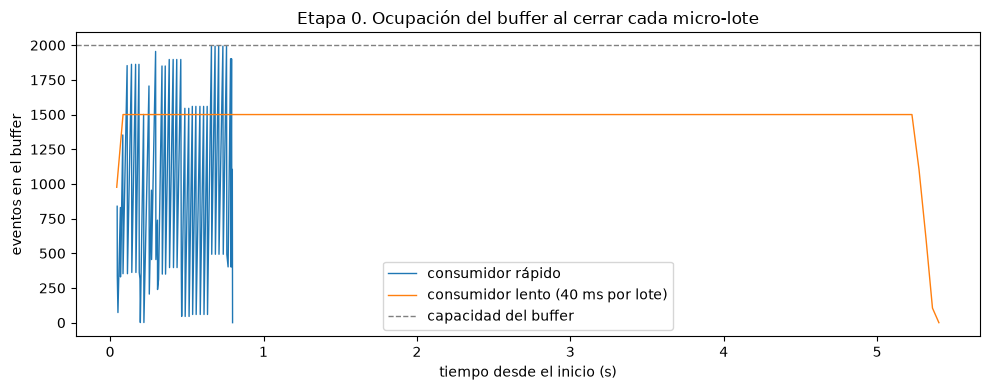

Ambos escenarios entregaron 64,105 eventos. El backpressure no perdió ninguno.


In [13]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(lotes_rapido["t_s"], lotes_rapido["ocupacion_buffer"], label="consumidor rápido", lw=1)
ax.plot(lotes_lento["t_s"], lotes_lento["ocupacion_buffer"], label="consumidor lento (40 ms por lote)", lw=1)
ax.axhline(metricas_lento["capacidad"], color="gray", ls="--", lw=1, label="capacidad del buffer")
ax.set_xlabel("tiempo desde el inicio (s)")
ax.set_ylabel("eventos en el buffer")
ax.set_title("Etapa 0. Ocupación del buffer al cerrar cada micro-lote")
ax.legend()
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / f"etapa0_ocupacion_buffer_{CATEGORIA}.png", dpi=150)
plt.show()

# Los dos escenarios procesan exactamente los mismos eventos (misma semilla)
assert metricas_rapido["eventos"] == metricas_lento["eventos"]
print(f"Ambos escenarios entregaron {metricas_rapido['eventos']:,} eventos. El backpressure no perdió ninguno.")

### Micro-lotes cerrados por tiempo

En los dos escenarios anteriores todos los lotes se cerraron por tamaño, porque el generador produce más de 500 eventos cada 50 ms. Para comprobar el cierre por tiempo se simula un stream de poco tráfico. Un productor pone un evento cada 2 ms, es decir, unos 25 eventos en cada ventana de 50 ms. Como el lote nunca alcanza 500 eventos, cada lote debe cerrarse por tiempo, y ningún evento debe esperar más de unos 50 ms en el buffer. En Windows la pausa real de time.sleep es algo mayor que 2 ms, por lo que cada lote reúne unos 20 eventos y no 25.

In [14]:
buffer_lento = BufferConBackpressure(capacidad=2_000)

def productor_poco_trafico(n_eventos=500, pausa_s=0.002):
    for i in range(n_eventos):
        buffer_lento.poner({"event_id": i, "llegada": time.perf_counter()})
        time.sleep(pausa_s)
    buffer_lento.cerrar()

hilo = threading.Thread(target=productor_poco_trafico, daemon=True)
hilo.start()
filas = []
for lote, motivo in micro_lotes(buffer_lento, tam_lote=500, max_espera_s=0.05):
    salida = time.perf_counter()
    filas.append({"tamano": len(lote), "motivo": motivo,
                  "espera_max_ms": (salida - min(e["llegada"] for e in lote)) * 1000})
hilo.join()

lotes_poco_trafico = pd.DataFrame(filas)
print(lotes_poco_trafico["motivo"].value_counts().to_dict())
lotes_poco_trafico.describe().round(1)

{'tiempo': 24}


,tamano,espera_max_ms
count,24.0,24.0
mean,20.8,48.9
std,1.0,1.3
min,19.0,47.5
25%,20.0,48.1
50%,21.0,48.5
75%,21.2,49.7
max,23.0,52.2


## Paso 8. Experimentos de complejidad

### Diseño del experimento

Se compara el costo de usar cuatro estructuras como cola FIFO.

| Estructura | `encolar` | `desencolar` | Costo esperado de n + n operaciones |
| --- | --- | --- | --- |
| `list` con `append` y `pop(0)` | O(1) amortizado | O(n) | O(n²) |
| `collections.deque` (línea base) | O(1) | O(1) | O(n) |
| `ColaEnlazada` (propia) | O(1) | O(1) | O(n) |
| `ColaCircular` (propia) | O(1) | O(1) | O(n) |

Cada medición encola n elementos y luego los desencola todos. Las decisiones del experimento son las siguientes.

- **Tamaños.** 1K, 10K, 100K, 1M y 10M, como pide el enunciado.
- **Repeticiones.** 100 para 1K y 10K, 20 para 100K, 5 para 1M y 3 para 10M. Se reducen en los tamaños grandes porque cada repetición tarda varios segundos y la desviación estándar ya es pequeña frente a la media.
- **Límite de `list.pop(0)`.** Se mide solo hasta 100K, con 5 repeticiones en ese tamaño. Por su costo O(n²), a 1M tardaría del orden de horas.
- **Elemento encolado.** Siempre es el mismo objeto, para medir solo el costo de la estructura y no el de crear elementos.
- **Recolector de basura.** Se desactiva durante cada medición (`gc.disable`). Así sus pausas no se mezclan con el tiempo de la estructura.
- **Reloj.** `time.perf_counter`, el reloj de mayor resolución disponible en Python.

Los resultados se guardan en `results/etapa0_cola_tiempos.csv`. Si el archivo ya existe, el notebook lo lee en lugar de repetir las mediciones. Para medir de nuevo se cambia `REEJECUTAR_EXPERIMENTOS` a `True`.

In [15]:
REEJECUTAR_EXPERIMENTOS = False
TAMANOS = [1_000, 10_000, 100_000, 1_000_000, 10_000_000]
REPETICIONES = {1_000: 100, 10_000: 100, 100_000: 20, 1_000_000: 5, 10_000_000: 3}
LIMITE_LISTA = 100_000          # list.pop(0) es O(n²): no se mide por encima de este tamaño
ELEMENTO = object()             # el mismo objeto en todas las operaciones


# Cada fábrica recibe n y devuelve las funciones (encolar, desencolar) de una cola nueva
def fabrica_lista(n):
    cola = []
    return cola.append, partial(cola.pop, 0)

def fabrica_deque(n):
    cola = deque()
    return cola.append, cola.popleft

def fabrica_enlazada(n):
    cola = ColaEnlazada()
    return cola.encolar, cola.desencolar

def fabrica_circular(n):
    cola = ColaCircular(n)
    return cola.encolar, cola.desencolar

ESTRUCTURAS = {
    "list.pop(0)": fabrica_lista,
    "collections.deque": fabrica_deque,
    "ColaEnlazada (propia)": fabrica_enlazada,
    "ColaCircular (propia)": fabrica_circular,
}


def medir_tiempo(fabrica, n):
    """Tiempo en segundos de n operaciones encolar seguidas de n operaciones desencolar."""
    encolar, desencolar = fabrica(n)
    gc.collect()
    gc.disable()
    try:
        t0 = time.perf_counter()
        for _ in range(n):
            encolar(ELEMENTO)
        for _ in range(n):
            desencolar()
        return time.perf_counter() - t0
    finally:
        gc.enable()


def repeticiones_para(nombre, n):
    if nombre == "list.pop(0)" and n >= LIMITE_LISTA:
        return min(REPETICIONES[n], 5)
    return REPETICIONES[n]


ruta_tiempos = CARPETA_RESULTADOS / "etapa0_cola_tiempos.csv"
if ruta_tiempos.exists() and not REEJECUTAR_EXPERIMENTOS:
    tiempos = pd.read_csv(ruta_tiempos)
    print(f"Resultados leídos de {ruta_tiempos.relative_to(RAIZ)}")
else:
    filas = []
    for n in TAMANOS:
        for nombre, fabrica in ESTRUCTURAS.items():
            if nombre == "list.pop(0)" and n > LIMITE_LISTA:
                continue
            for rep in range(repeticiones_para(nombre, n)):
                filas.append({"estructura": nombre, "n": n, "repeticion": rep,
                              "segundos": medir_tiempo(fabrica, n)})
        print(f"n = {n:>10,} medido")
    tiempos = pd.DataFrame(filas)
    tiempos.to_csv(ruta_tiempos, index=False)
    print(f"Resultados guardados en {ruta_tiempos.relative_to(RAIZ)}")

resumen = (tiempos.groupby(["estructura", "n"])["segundos"]
           .agg(promedio_s="mean", desv_est_s="std", repeticiones="count").reset_index())
resumen["ns_por_operacion"] = resumen["promedio_s"] / (2 * resumen["n"]) * 1e9
resumen

Resultados leídos de results\etapa0_cola_tiempos.csv


,estructura,n,promedio_s,desv_est_s,repeticiones,ns_por_operacion
0,ColaCircular (propia),1000,0.000461,0.000047,100,230.386500
1,ColaCircular (propia),10000,0.005209,0.000503,100,260.436200
2,ColaCircular (propia),100000,0.039854,0.000625,20,199.269200
3,ColaCircular (propia),1000000,0.393899,0.012907,5,196.949720
4,ColaCircular (propia),10000000,3.769137,0.038300,3,188.456825
5,ColaEnlazada (propia),1000,0.000547,0.000283,100,273.607500
6,ColaEnlazada (propia),10000,0.004990,0.000768,100,249.478550
7,ColaEnlazada (propia),100000,0.041346,0.001338,20,206.729425
8,ColaEnlazada (propia),1000000,0.408136,0.006215,5,204.067760
9,ColaEnlazada (propia),10000000,4.464754,0.380783,3,223.237718


### Escalabilidad en escala log-log

En una gráfica log-log, un costo de la forma T(n) = c·nᵏ aparece como una recta de pendiente k. Una estructura O(n) debe mostrar pendiente cercana a 1 y una O(n²) pendiente cercana a 2. Las líneas punteadas son las referencias teóricas, ancladas en el primer punto de `ColaCircular` y de `list.pop(0)`.

La gráfica de la derecha muestra el tiempo por operación. Si cada operación es O(1), esa curva se mantiene casi plana al crecer n.

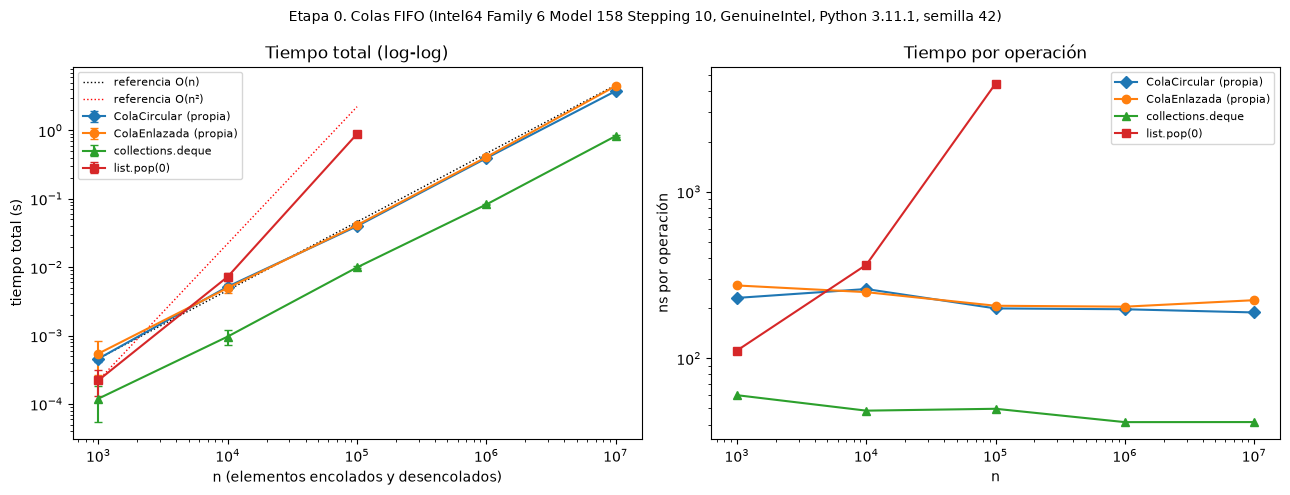

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
marcadores = {"list.pop(0)": "s", "collections.deque": "^",
              "ColaEnlazada (propia)": "o", "ColaCircular (propia)": "D"}

for nombre, datos in resumen.groupby("estructura"):
    ax1.errorbar(datos["n"], datos["promedio_s"], yerr=datos["desv_est_s"],
                 marker=marcadores[nombre], capsize=3, label=nombre)
    ax2.plot(datos["n"], datos["ns_por_operacion"], marker=marcadores[nombre], label=nombre)

# Referencias teóricas
n_ref = np.array(TAMANOS, dtype=float)
base_circ = resumen.query("estructura == 'ColaCircular (propia)'").iloc[0]
base_lista = resumen.query("estructura == 'list.pop(0)'").iloc[0]
ax1.plot(n_ref, base_circ["promedio_s"] * n_ref / base_circ["n"], "k:", lw=1, label="referencia O(n)")
n_lista = n_ref[n_ref <= LIMITE_LISTA]
ax1.plot(n_lista, base_lista["promedio_s"] * (n_lista / base_lista["n"]) ** 2, "r:", lw=1,
         label="referencia O(n²)")

ax1.set_xscale("log"); ax1.set_yscale("log")
ax1.set_xlabel("n (elementos encolados y desencolados)"); ax1.set_ylabel("tiempo total (s)")
ax1.set_title("Tiempo total (log-log)")
ax1.legend(fontsize=8)

ax2.set_xscale("log"); ax2.set_yscale("log")
ax2.set_xlabel("n"); ax2.set_ylabel("ns por operación")
ax2.set_title("Tiempo por operación")
ax2.legend(fontsize=8)

plt.suptitle(f"Etapa 0. Colas FIFO ({PLATAFORMA['procesador']}, Python {PLATAFORMA['python']}, semilla {SEED})",
             fontsize=10)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "etapa0_escalabilidad.png", dpi=150)
plt.show()

### Pendiente empírica

Se ajusta una recta a log(tiempo) frente a log(n) con mínimos cuadrados (`np.polyfit`). La pendiente estimada se compara con el exponente teórico.

In [17]:
TEORICO = {"list.pop(0)": 2, "collections.deque": 1, "ColaEnlazada (propia)": 1, "ColaCircular (propia)": 1}

pendientes = []
for nombre, datos in resumen.groupby("estructura"):
    k, _ = np.polyfit(np.log10(datos["n"]), np.log10(datos["promedio_s"]), 1)
    pendientes.append({"estructura": nombre, "pendiente_empirica": round(k, 2),
                       "exponente_teorico": TEORICO[nombre],
                       "rango_n": f"{datos['n'].min():,} a {datos['n'].max():,}"})
pd.DataFrame(pendientes)

,estructura,pendiente_empirica,exponente_teorico,rango_n
0,ColaCircular (propia),0.97,1,"1,000 a 10,000,000"
1,ColaEnlazada (propia),0.97,1,"1,000 a 10,000,000"
2,collections.deque,0.96,1,"1,000 a 10,000,000"
3,list.pop(0),1.80,2,"1,000 a 100,000"


### Memoria actual y pico

Se mide con `tracemalloc` la memoria que ocupa cada cola después de encolar n elementos (memoria actual) y la memoria máxima alcanzada durante todo el proceso (memoria pico). Como el elemento encolado es siempre el mismo objeto, la cifra corresponde solo a la estructura. La memoria se mide hasta 1M porque `tracemalloc` registra cada asignación y a 10M multiplica el tiempo y la memoria de la medición. Al ser O(n), el valor a 10M se puede extrapolar multiplicando por 10.

Se espera que `ColaCircular` use unos 8 bytes por elemento (una referencia en el arreglo) y que `ColaEnlazada` use bastante más, porque cada nodo es un objeto completo.

In [18]:
def medir_memoria(fabrica, n):
    """Devuelve (memoria con n elementos encolados, memoria pico) en bytes."""
    gc.collect()
    tracemalloc.start()
    encolar, desencolar = fabrica(n)
    for _ in range(n):
        encolar(ELEMENTO)
    actual, _ = tracemalloc.get_traced_memory()
    for _ in range(n):
        desencolar()
    _, pico = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return actual, pico


ruta_memoria = CARPETA_RESULTADOS / "etapa0_cola_memoria.csv"
if ruta_memoria.exists() and not REEJECUTAR_EXPERIMENTOS:
    memoria = pd.read_csv(ruta_memoria)
else:
    filas = []
    for n in [1_000, 10_000, 100_000, 1_000_000]:
        for nombre, fabrica in ESTRUCTURAS.items():
            if nombre == "list.pop(0)" and n > LIMITE_LISTA:
                continue
            actual, pico = medir_memoria(fabrica, n)
            filas.append({"estructura": nombre, "n": n, "actual_mb": actual / 1e6, "pico_mb": pico / 1e6})
    memoria = pd.DataFrame(filas)
    memoria.to_csv(ruta_memoria, index=False)

memoria["bytes_por_elemento"] = memoria["pico_mb"] * 1e6 / memoria["n"]
memoria.pivot(index="n", columns="estructura", values="bytes_por_elemento").round(1)

estructura,ColaCircular (propia),ColaEnlazada (propia),collections.deque,list.pop(0)
n,,,,
1000,8.7,48.5,9.6,9.4
10000,8.1,48.1,8.4,8.6
100000,8.0,48.0,8.3,8.0
1000000,8.0,48.0,8.3,NaN


### Lectura de los resultados

Los valores citados corresponden a la ejecución guardada en `results/`. Al medir de nuevo pueden variar ligeramente.

- `ColaCircular`, `ColaEnlazada` y `deque` muestran pendientes cercanas a 1 (entre 0.96 y 0.97) y un tiempo por operación casi constante entre 1K y 10M. Esto confirma el costo O(1) por operación y O(n) en total.
- `list.pop(0)` muestra un tiempo por operación que crece con n, de unos 110 ns a 1K hasta unos 4 400 ns a 100K. Su pendiente global es 1.8 y no 2 porque a 1K el costo fijo del bucle de Python domina sobre el desplazamiento de elementos. Entre 10K y 100K, donde domina el desplazamiento, el tiempo crece unas 120 veces cuando n crece 10 veces, lo que corresponde a una pendiente cercana a 2.
- `deque` es unas 4 a 5 veces más rápida que las colas propias porque está implementada en C, mientras que las propias se ejecutan como código Python interpretado. La diferencia es un factor constante y no cambia el orden de complejidad.
- En memoria, `ColaCircular` usa 8 bytes por elemento, igual que `deque` y `list`, porque solo guarda una referencia por posición. `ColaEnlazada` usa unos 48 bytes por elemento, seis veces más, porque cada nodo es un objeto de Python.

Por estas razones, el buffer de la etapa 0 usa `ColaCircular`. Su costo es O(1) por operación, su memoria es fija y conocida, y su capacidad acotada permite aplicar backpressure. `ColaEnlazada` se reserva para colas sin límite, como la cola de rechazados de la etapa 1.

## Paso 9. Salida de la etapa 0 para la etapa 1

La etapa 0 entrega micro-lotes de registros crudos. Mientras cada etapa esté en su propio notebook, la salida se guarda en archivos dentro de `data/interim/<CATEGORIA>/`, que no se versiona. Al terminar, la etapa escribe la categoría en `data/interim/categoria_actual.txt`; las etapas 1 y 2 leen esa marca para saber qué carpeta procesar. El notebook de la etapa 1 los leerá lote por lote.

| Archivo | Contenido | Lo usa |
| --- | --- | --- |
| `etapa0_lotes.jsonl` | Una línea por micro-lote con su número y sus registros crudos | Etapa 1 |
| `etapa0_inyecciones.json` | Conteos de duplicados, malformados y tardíos inyectados (verdad de referencia) | Etapa 1, para medir la deduplicación y la validación |
| `listas_senalados.json` | Cuentas, tarjetas y dispositivos señalados | Etapa 6 (Bloom Filter) |

Se procesan 20 000 reseñas. La función `guardar_lote` cumple el papel de la etapa 1 dentro de `ejecutar_etapa0`, lo que muestra cómo se conectarán las etapas.

In [19]:
N_RESENAS_SALIDA = 20_000
ruta_lotes = CARPETA_INTERIM / "etapa0_lotes.jsonl"

with open(ruta_lotes, "w", encoding="utf-8") as archivo_lotes:
    def guardar_lote(numero, lote):
        archivo_lotes.write(json.dumps({"lote": numero, "registros": lote}) + "\n")

    metricas_salida, lotes_salida, generador_salida = ejecutar_etapa0(
        N_RESENAS_SALIDA, al_recibir_lote=guardar_lote)

inyecciones = dict(generador_salida.estadisticas)
inyecciones.update(n_resenas=N_RESENAS_SALIDA, semilla=SEED)
(CARPETA_INTERIM / "etapa0_inyecciones.json").write_text(json.dumps(inyecciones, indent=2), encoding="utf-8")
(CARPETA_INTERIM / "listas_senalados.json").write_text(
    json.dumps(generador_salida.listas_senalados(), indent=2), encoding="utf-8")

# Marca para las etapas 1 y 2: la última categoría con salida completa de la etapa 0
(CARPETA_INTERIM.parent / "categoria_actual.txt").write_text(CATEGORIA, encoding="utf-8")

print(f"Archivo de lotes: {ruta_lotes.relative_to(RAIZ)}  ({ruta_lotes.stat().st_size / 1e6:.1f} MB)")
pd.Series(metricas_salida, name="valor").to_frame()

Archivo de lotes: data\interim\All_Beauty\etapa0_lotes.jsonl  (41.7 MB)


,valor
eventos,134277.00
lotes,269.00
lotes_por_tamano,268.00
lotes_por_tiempo,0.00
duracion_s,2.46
eventos_por_s,54474.00
bloqueos_productor,167.00
espera_productor_s,0.43
ocupacion_maxima,2000.00
capacidad,2000.00


### Verificación de la salida

Se vuelve a leer el archivo para confirmar que el número de eventos guardados coincide con el número de eventos emitidos por el generador.

In [20]:
total_guardado = 0
with open(ruta_lotes, encoding="utf-8") as f:
    for linea in f:
        total_guardado += len(json.loads(linea)["registros"])

assert total_guardado == inyecciones["emitidos"] == metricas_salida["eventos"]
print(f"Eventos emitidos por el generador: {inyecciones['emitidos']:,}")
print(f"Eventos guardados en {metricas_salida['lotes']} lotes: {total_guardado:,}")
print("La etapa 0 entregó todos los eventos, sin pérdidas.")

Eventos emitidos por el generador: 134,277
Eventos guardados en 269 lotes: 134,277
La etapa 0 entregó todos los eventos, sin pérdidas.


## Resumen de la etapa 0

| Aspecto | Decisión |
| --- | --- |
| Lectura del dataset | Generador de Python sobre el JSONL; memoria O(1) respecto al número de reseñas |
| Estructura del buffer | `ColaCircular` propia, capacidad fija, `encolar` y `desencolar` en O(1) |
| Estructura alternativa | `ColaEnlazada` propia, sin límite, para la cola de rechazados de la etapa 1 |
| Concurrencia | Productor en un hilo, consumidor en el hilo principal, sincronizados con `Lock` y `Condition` |
| Backpressure | El productor se bloquea si el buffer está lleno; no se pierden eventos y la memoria queda acotada |
| Micro-lotes | Se cierran al llegar a 500 eventos o al pasar 50 ms, lo que ocurra primero |
| Salida | Micro-lotes de registros crudos en `data/interim/<CATEGORIA>/etapa0_lotes.jsonl` |

Referencias. Cormen, T. H., Leiserson, C. E., Rivest, R. L., y Stein, C. (2022). *Introduction to Algorithms* (4.ª ed.), cap. 10. Leskovec, J., Rajaraman, A., y Ullman, J. D. (2020). *Mining of Massive Datasets* (3.ª ed.), cap. 4.